### Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

### Obtain Dataset

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()  

In [3]:
print("Training data shape:", x_train.shape, y_train.shape)
print("Testing data shape:", x_test.shape, y_test.shape)

Training data shape: (50000, 32, 32, 3) (50000, 1)
Testing data shape: (10000, 32, 32, 3) (10000, 1)


In [4]:
# x_train 

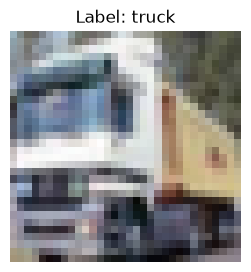

In [5]:
# Display a sample image
class_names = ["airplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]

plt.figure(figsize=(3, 3))
plt.imshow(x_train[1], interpolation="nearest")   # no smoothing
plt.title(f"Label: {class_names[y_train[1][0]]}")
plt.axis("off")
plt.show()

### Data Preprocessing

In [6]:
# Normalisation
x_train = x_train.astype("float32") / 255.0
x_test  = x_test.astype("float32") / 255.0

In [7]:
# Flatten the images for the fully connected layers
# CIFAR-10 images are 32x32 pixels with 3 colour channels (RGB),
# so each image becomes a vector of 32*32*3 = 3072 values
x_train = x_train.reshape(-1, 32 * 32 * 3)
x_test  = x_test.reshape(-1, 32 * 32 * 3)

# Labels come as shape (n, 1); flatten them to shape (n,)
y_train = y_train.flatten()
y_test  = y_test.flatten()

print("New shape of training data:", x_train.shape)
print("New shape of test data:", x_test.shape)

New shape of training data: (50000, 3072)
New shape of test data: (10000, 3072)


### Simple FNN

In [8]:
input_shape = x_train.shape[1]  

In [9]:
keras.utils.set_random_seed(42)

In [10]:
# Define a simple fully connected neural network
model1 = keras.Sequential([
                            layers.Dense(32, activation="relu", input_shape=(input_shape,)), # Single hidden layer
                            layers.Dense(10, activation="softmax") # Output layer for classification
                            ])

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [11]:
# Compile the model
model1.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

In [12]:
history1 = model1.fit(x_train, y_train, epochs=50, validation_data=(x_test, y_test))

Epoch 1/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 1s 653us/step - accuracy: 0.1884 - loss: 2.1239 - val_accuracy: 0.2068 - val_loss: 2.0362
Epoch 2/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 1s 620us/step - accuracy: 0.2295 - loss: 2.0148 - val_accuracy: 0.2370 - val_loss: 1.9870
Epoch 3/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 1s 607us/step - accuracy: 0.2474 - loss: 1.9738 - val_accuracy: 0.2455 - val_loss: 1.9559
Epoch 4/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 1s 607us/step - accuracy: 0.2528 - loss: 1.9525 - val_accuracy: 0.2500 - val_loss: 1.9416
Epoch 5/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 1s 627us/step - accuracy: 0.2541 - loss: 1.9431 - val_accuracy: 0.2546 - val_loss: 1.9306
Epoch 6/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 1s 608us/step - accuracy: 0.2542 - loss: 1.9376 - val_accuracy: 0.2544 - val_loss: 1.9259
Epoch 7/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 1s 597us/step - accuracy: 0.2544 - loss: 1.9337 - val_accuracy: 0.2550 - val_loss: 1.9237
Epoch 8/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 1s 611us/step - accuracy: 0.2544 -

In [13]:
# Evaluate the model
test_loss, test_acc = model1.evaluate(x_test, y_test)
print(f"Test Accuracy: {test_acc:.4f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 302us/step - accuracy: 0.2620 - loss: 1.9087
Test Accuracy: 0.2620


### Deeper FNN

In [14]:
# Define a deeper fully connected neural network
model2 = keras.Sequential([
                            keras.Input(shape=(input_shape,)),     # Input layer (3072 features)
                            layers.Dense(128, activation="relu"),   # First hidden layer
                            layers.Dense(64, activation="relu"),    # Second hidden layer
                            layers.Dense(32, activation="relu"),    # Third hidden layer
                            layers.Dense(10, activation="softmax")  # Output layer
                        ])

In [15]:
# Compile model
model2.compile(optimizer="adam",
                loss="sparse_categorical_crossentropy",
                metrics=["accuracy"])

In [16]:
# Train the model
history2 = model2.fit(x_train, y_train, epochs=50, validation_data=(x_test, y_test))

Epoch 1/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.3042 - loss: 1.9062 - val_accuracy: 0.3601 - val_loss: 1.7781
Epoch 2/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.3832 - loss: 1.7137 - val_accuracy: 0.3977 - val_loss: 1.6722
Epoch 3/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.4146 - loss: 1.6369 - val_accuracy: 0.4344 - val_loss: 1.5824
Epoch 4/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.4316 - loss: 1.5880 - val_accuracy: 0.4440 - val_loss: 1.5571
Epoch 5/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.4455 - loss: 1.5494 - val_accuracy: 0.4523 - val_loss: 1.5347
Epoch 6/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.4551 - loss: 1.5207 - val_accuracy: 0.4560 - val_loss: 1.5177
Epoch 7/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.4645 - loss: 1.4957 - val_accuracy: 0.4644 - val_loss: 1.5108
Epoch 8/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.4723 - loss: 1.4764 - 

In [17]:
# Evaluate the model
test_loss, test_acc = model2.evaluate(x_test, y_test)
print(f"Test Accuracy: {test_acc:.4f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 386us/step - accuracy: 0.4634 - loss: 1.5770
Test Accuracy: 0.4634


Text(0.5, 1.0, 'Training & Validation Accuracy')

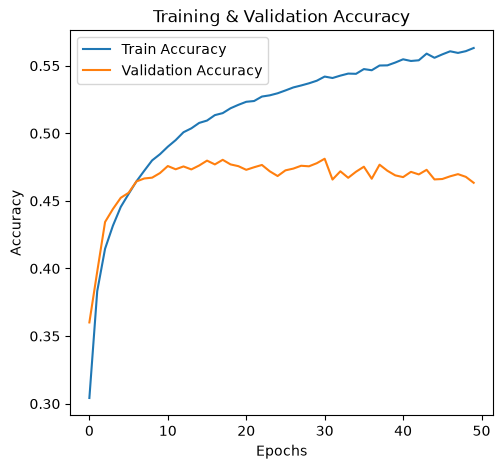

In [18]:
# Plot training history
plt.figure(figsize=(12, 5))
# Accuracy plot
plt.subplot(1, 2, 1)
plt.plot(history2.history['accuracy'], label='Train Accuracy')
plt.plot(history2.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.title("Training & Validation Accuracy")

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 321us/step


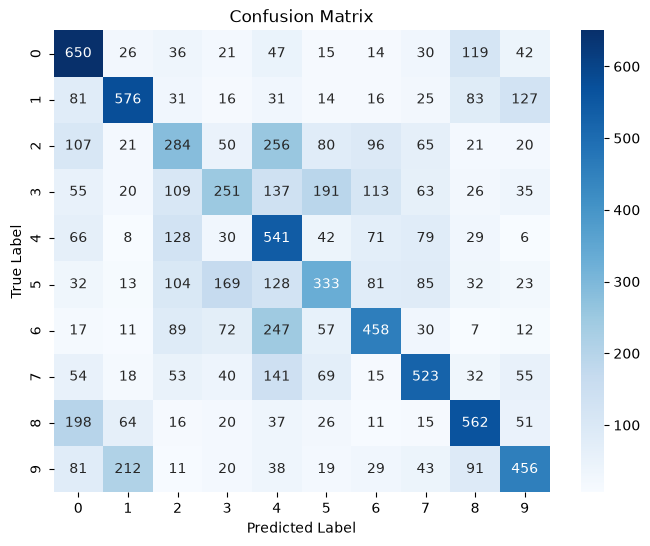

In [19]:
import seaborn as sns

# Generate predictions
y_pred = model2.predict(x_test).argmax(axis=1)
# Compute confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)
# Plot confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=range(10), yticklabels=range(10))
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()